In [1]:

import pandas as pd

files = [
    "2024_LoL_esports_match_data_from_OraclesElixir.csv",
    "2025_LoL_esports_match_data_from_OraclesElixir.csv",
    "2026_LoL_esports_match_data_from_OraclesElixir.csv"
]

df = pd.concat(
    [pd.read_csv(file, low_memory=False) for file in files],
    ignore_index=True
)

# Keep team-level records only
team_df = df[df["position"] == "team"].copy()

# Count unique games by league or tournament
league_counts = (
    team_df.groupby("league")["gameid"]
    .nunique()
    .sort_values(ascending=False)
)

print("Total unique games:", team_df["gameid"].nunique())

print("\nInternational tournaments:")
print(
    league_counts[
        league_counts.index.isin(["MSI", "WLDs", "FST"])
    ]
)


Total unique games: 30105

International tournaments:
league
WLDs    313
MSI     229
FST      80
Name: gameid, dtype: int64


In [2]:

# List all league codes and their unique match counts

league_summary = (
    team_df.groupby("league")["gameid"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="matches")
)

print("Total league codes:", len(league_summary))

display(league_summary.head(40))


Total league codes: 71


,league,matches
0,LPL,2196
1,LCKC,1544
2,LCK,1539
3,EM,1362
4,LAS,1334
5,NACL,1044
6,LEC,985
7,LJL,885
8,PRM,864
9,LFL,830


In [3]:

# Check domestic leagues and international tournaments by year

selected_leagues = [
    "LCK", "LPL", "LEC",
    "LCS", "LTA", "CBLOL",
    "PCS", "VCS", "LJL", "LCP",
    "MSI", "WLDs", "FST"
]

check_df = team_df[
    team_df["league"].isin(selected_leagues)
].copy()

check_df["year"] = pd.to_datetime(
    check_df["date"]
).dt.year

league_year_counts = (
    check_df.groupby(["league", "year"])["gameid"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(selected_leagues, fill_value=0)
)

display(league_year_counts)

print(
    "Total unique selected games:",
    check_df["gameid"].nunique()
)


year,2024,2025,2026
league,,,
LCK,482,555,502
LPL,717,805,674
LEC,294,308,383
LCS,192,0,283
LTA,0,40,0
CBLOL,263,0,299
PCS,297,302,86
VCS,252,141,155
LJL,148,374,363


Total unique selected games: 9111


In [4]:

# Compare team names in international tournaments
# with team names in domestic leagues

international_codes = ["MSI", "WLDs", "FST"]

domestic_codes = [
    "LCK", "LPL", "LEC",
    "LCS", "LTA", "CBLOL",
    "PCS", "VCS", "LJL", "LCP"
]

international_teams = set(
    team_df.loc[
        team_df["league"].isin(international_codes),
        "teamname"
    ].dropna().unique()
)

domestic_teams = set(
    team_df.loc[
        team_df["league"].isin(domestic_codes),
        "teamname"
    ].dropna().unique()
)

matched = international_teams & domestic_teams
unmatched = international_teams - domestic_teams

print("International teams:", len(international_teams))
print("Matched with domestic leagues:", len(matched))
print("Not matched:", len(unmatched))

print("\nInternational team names without an exact match:")
for team in sorted(unmatched):
    print("-", team)


International teams: 40
Matched with domestic leagues: 39
Not matched: 1

International team names without an exact match:
- Movistar R7


In [5]:

# Find all records for Movistar R7 and related team names

names_to_check = [
    "Movistar R7",
    "Rainbow7",
    "LYON",
    "Lyon Gaming",
    "Six Karma"
]

team_check = team_df[
    team_df["teamname"].str.contains(
        "Movistar R7|Rainbow7|LYON|Lyon Gaming|Six Karma",
        case=False,
        na=False
    )
].copy()

team_check["year"] = pd.to_datetime(
    team_check["date"]
).dt.year

summary = (
    team_check.groupby(["teamname", "league", "year"])
    ["gameid"]
    .nunique()
    .reset_index(name="matches")
    .sort_values(["teamname", "year", "league"])
)

display(summary)


,teamname,league,year,matches
3,LYON,LTA N,2025,33
0,LYON,EWC,2026,11
1,LYON,FST,2026,12
2,LYON,LCS,2026,82
4,LYON,MSI,2026,17
5,LYON,WLDs,2026,11
6,LYON Academy,LRN,2025,31
7,LYON Academy,LRN,2026,33
8,Movistar R7,LLA,2024,73
9,Movistar R7,WLDs,2024,8


In [6]:

# Inspect additional leagues and tournament coverage

extra_codes = ["LLA", "LTA N", "LTA S", "EWC"]

extra_df = team_df[
    team_df["league"].isin(extra_codes)
].copy()

extra_df["year"] = pd.to_datetime(
    extra_df["date"]
).dt.year

extra_summary = (
    extra_df.groupby(["league", "year"])["gameid"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(extra_codes, fill_value=0)
)

display(extra_summary)

print(
    "Total unique games:",
    extra_df["gameid"].nunique()
)


year,2024,2025,2026
league,,,
LLA,213,0,0
LTA N,0,214,0
LTA S,0,222,0
EWC,19,33,232


Total unique games: 933


In [7]:

# Inspect EWC participants by year

ewc_df = team_df[
    team_df["league"] == "EWC"
].copy()

ewc_df["year"] = pd.to_datetime(
    ewc_df["date"]
).dt.year

ewc_summary = (
    ewc_df.groupby("year")
    .agg(
        matches=("gameid", "nunique"),
        teams=("teamname", "nunique"),
        first_match=("date", "min"),
        last_match=("date", "max")
    )
    .reset_index()
)

display(ewc_summary)

for year in sorted(ewc_df["year"].unique()):
    teams = sorted(
        ewc_df.loc[
            ewc_df["year"] == year,
            "teamname"
        ].dropna().unique()
    )

    print(f"\n{year} EWC teams ({len(teams)}):")
    print(", ".join(teams))


,year,matches,teams,first_match,last_match
0,2024,19,8,2024-07-04 15:07:08,2024-07-07 19:38:09
1,2025,33,12,2025-07-16 09:32:34,2025-07-20 15:29:19
2,2026,232,50,2026-04-14 18:07:58,2026-07-19 15:15:31



2024 EWC teams (8):
Bilibili Gaming, FlyQuest, Fnatic, G2 Esports, Gen.G, T1, Team Liquid, Top Esports

2025 EWC teams (12):
Anyone's Legend, Bilibili Gaming, CTBC Flying Oyster, Cloud9, FURIA, FlyQuest, G2 Esports, GAM Esports, Gen.G, Hanwha Life Esports, Movistar KOI, T1

2026 EWC teams (50):
Anyone's Legend, BNK FEARX, Bilibili Gaming, CTBC Flying Oyster, Cloud9, DN SOOPers, Deep Cross Gaming, DetonatioN FocusMe, Dignitas, Disguised, Dplus Kia, FURIA, Fluxo W7M, FlyQuest, Fnatic, Fukuoka SoftBank HAWKS gaming, G2 Esports, GAM Esports, Galions, Gen.G, GiantX, Ground Zero Gaming, HANJIN BRION, Hanwha Life Esports, JD Gaming, KT Rolster, Karmine Corp, Kiwoom DRX, LOUD, LYON, Leviatan, LØS, MVK Esports, Movistar KOI, Natus Vincere, Nongshim RedForce, RED Canids, SK Gaming, Sentinels, Shifters, Shopify Rebellion, Solary, T1, Team Heretics, Team Liquid, Team Secret, Team Secret Whales, Team Vitality, Vivo Keyd Stars, paiN Gaming


In [8]:

# Inspect EWC 2026 match distribution by month

ewc_2026 = ewc_df[
    ewc_df["year"] == 2026
].copy()

ewc_2026["date"] = pd.to_datetime(
    ewc_2026["date"]
)

ewc_2026["month"] = (
    ewc_2026["date"].dt.to_period("M").astype(str)
)

monthly_summary = (
    ewc_2026.groupby("month")
    .agg(
        matches=("gameid", "nunique"),
        teams=("teamname", "nunique"),
        first_match=("date", "min"),
        last_match=("date", "max")
    )
    .reset_index()
)

display(monthly_summary)


,month,matches,teams,first_match,last_match
0,2026-04,60,20,2026-04-14 18:07:58,2026-04-30 18:01:57
1,2026-05,91,26,2026-05-04 07:16:19,2026-05-26 09:01:18
2,2026-06,30,7,2026-06-07 16:06:52,2026-06-14 18:09:05
3,2026-07,51,16,2026-07-15 09:41:28,2026-07-19 15:15:31


In [9]:

# Inspect teams in the July 2026 EWC matches

ewc_july = ewc_2026[
    ewc_2026["date"].dt.month == 7
].copy()

teams_july = sorted(
    ewc_july["teamname"].dropna().unique()
)

print("July 2026 EWC matches:", ewc_july["gameid"].nunique())
print("Number of teams:", len(teams_july))

print("\nTeams:")
for team in teams_july:
    print("-", team)


July 2026 EWC matches: 51
Number of teams: 16

Teams:
- Anyone's Legend
- Bilibili Gaming
- Dplus Kia
- FURIA
- G2 Esports
- GAM Esports
- Gen.G
- Hanwha Life Esports
- JD Gaming
- Karmine Corp
- LYON
- LØS
- Movistar KOI
- Sentinels
- T1
- Team Secret


In [10]:

import pandas as pd

domestic_codes = [
    "LCK", "LPL", "LEC",
    "LCS", "LTA", "LTA N", "LTA S",
    "CBLOL", "PCS", "VCS", "LJL",
    "LCP", "LLA"
]

international_codes = ["MSI", "WLDs", "FST"]

# Convert dates
team_df["date"] = pd.to_datetime(team_df["date"])

# Domestic league matches
domestic = team_df[
    team_df["league"].isin(domestic_codes)
].copy()

# International tournament matches
international = team_df[
    team_df["league"].isin(international_codes)
].copy()

# EWC: retain 2024-2025 and July 2026
ewc_main = team_df[
    (team_df["league"] == "EWC") &
    (
        (team_df["date"].dt.year.isin([2024, 2025])) |
        (
            (team_df["date"].dt.year == 2026) &
            (team_df["date"].dt.month == 7)
        )
    )
].copy()

# Combine selected competitions
v4_team_df = pd.concat(
    [domestic, international, ewc_main],
    ignore_index=True
)

print("Domestic games:", domestic["gameid"].nunique())
print("International games:", international["gameid"].nunique())
print("EWC main-event candidate games:", ewc_main["gameid"].nunique())

print("\nTotal V4 unique games:", v4_team_df["gameid"].nunique())
print("Team-level rows:", len(v4_team_df))


Domestic games: 9138
International games: 622
EWC main-event candidate games: 103

Total V4 unique games: 9863
Team-level rows: 19726


In [11]:

# STEP 11: Validate and create match-level V4 data

# Check that each game has exactly two team records
team_counts = v4_team_df.groupby("gameid").size()

# Check that exactly one team won each game
win_counts = v4_team_df.groupby("gameid")["result"].sum()

valid_ids = team_counts[
    (team_counts == 2) & (win_counts == 1)
].index

invalid_ids = team_counts.index.difference(valid_ids)

print("Total games:", len(team_counts))
print("Valid games:", len(valid_ids))
print("Invalid games:", len(invalid_ids))

# Keep valid games only
clean_v4 = v4_team_df[
    v4_team_df["gameid"].isin(valid_ids)
].copy()

# Blue team records
blue = clean_v4[
    clean_v4["side"] == "Blue"
][["gameid", "date", "league", "teamname", "result"]].rename(
    columns={
        "teamname": "blue_team",
        "result": "blue_win"
    }
)

# Red team records
red = clean_v4[
    clean_v4["side"] == "Red"
][["gameid", "teamname"]].rename(
    columns={"teamname": "red_team"}
)

# Merge into one row per game
v4_matches = blue.merge(
    red,
    on="gameid",
    how="inner",
    validate="one_to_one"
)

v4_matches = v4_matches.sort_values(
    ["date", "gameid"]
).reset_index(drop=True)

v4_matches["year"] = v4_matches["date"].dt.year

print("\nFinal match-level shape:", v4_matches.shape)

display(v4_matches.head())


Total games: 9863
Valid games: 9863
Invalid games: 0

Final match-level shape: (9863, 7)


,gameid,date,league,blue_team,blue_win,red_team,year
0,LOLTMNT06_13630,2024-01-13 16:10:20,LEC,Team BDS,0,G2 Esports,2024
1,LOLTMNT06_12701,2024-01-13 17:06:48,LEC,Rogue,0,SK Gaming,2024
2,LOLTMNT06_13667,2024-01-13 18:15:52,LEC,Karmine Corp,0,Fnatic,2024
3,LOLTMNT06_12743,2024-01-13 19:24:48,LEC,Team Vitality,0,GiantX,2024
4,LOLTMNT06_13695,2024-01-13 20:28:03,LEC,MAD Lions KOI,1,Team Heretics,2024


In [12]:

# Check Blue/Red side integrity for every game

side_counts = (
    v4_team_df.groupby(["gameid", "side"])
    .size()
    .unstack(fill_value=0)
)

invalid_sides = side_counts[
    (side_counts.get("Blue", 0) != 1) |
    (side_counts.get("Red", 0) != 1)
]

print("Total games checked:", len(side_counts))
print("Games with invalid Blue/Red structure:", len(invalid_sides))

print("Match-level rows:", len(v4_matches))
print("Unique match IDs:", v4_matches["gameid"].nunique())
print("Duplicate match IDs:", v4_matches["gameid"].duplicated().sum())
print("Chronological order:", v4_matches["date"].is_monotonic_increasing)


Total games checked: 9863
Games with invalid Blue/Red structure: 0
Match-level rows: 9863
Unique match IDs: 9863
Duplicate match IDs: 0
Chronological order: True


In [13]:

# STEP 13: Inspect team names across years and competitions

team_names = pd.concat([
    v4_matches[
        ["year", "league", "blue_team"]
    ].rename(columns={"blue_team": "team"}),

    v4_matches[
        ["year", "league", "red_team"]
    ].rename(columns={"red_team": "team"})
], ignore_index=True)

# Summarise each team's recorded competitions
team_summary = (
    team_names.groupby("team")
    .agg(
        years=("year", lambda x: ", ".join(
            map(str, sorted(x.unique()))
        )),
        leagues=("league", lambda x: ", ".join(
            sorted(x.unique())
        ))
    )
    .reset_index()
)

# Focus on teams appearing in international tournaments
international_teams = set(
    team_names.loc[
        team_names["league"].isin(
            ["MSI", "WLDs", "FST", "EWC"]
        ),
        "team"
    ]
)

international_team_summary = (
    team_summary[
        team_summary["team"].isin(international_teams)
    ]
    .sort_values("team")
    .reset_index(drop=True)
)

print(
    "International team identities:",
    len(international_team_summary)
)

display(international_team_summary)


International team identities: 42


,team,years,leagues
0,100 Thieves,"2024, 2025","LCS, LTA, LTA N, WLDs"
1,Anyone's Legend,"2024, 2025, 2026","EWC, LPL, MSI, WLDs"
2,BNK FEARX,"2024, 2025, 2026","FST, LCK, WLDs"
3,Bilibili Gaming,"2024, 2025, 2026","EWC, FST, LPL, MSI, WLDs"
4,CTBC Flying Oyster,"2024, 2025, 2026","EWC, FST, LCP, MSI, PCS, WLDs"
5,Cloud9,"2024, 2025, 2026","EWC, LCS, LTA, LTA N, WLDs"
6,Deep Cross Gaming,"2024, 2025, 2026","LCP, MSI, PCS"
7,Dplus Kia,"2024, 2025, 2026","EWC, LCK, WLDs"
8,Estral Esports,"2024, 2025, 2026","CBLOL, LLA, LTA N, MSI"
9,FURIA,"2024, 2025, 2026","CBLOL, EWC, LTA S, MSI, WLDs"


In [14]:

# STEP 14: Create canonical team names for V4

v4_clean = v4_matches.copy()

team_name_map = {
    "MAD Lions KOI": "Movistar KOI",
    "Team BDS": "Shifters"
}

# Preserve original team names
v4_clean["blue_team_original"] = v4_clean["blue_team"]
v4_clean["red_team_original"] = v4_clean["red_team"]

# Apply canonical names for Elo modelling
v4_clean["blue_team"] = (
    v4_clean["blue_team"].replace(team_name_map)
)

v4_clean["red_team"] = (
    v4_clean["red_team"].replace(team_name_map)
)

print("Total games:", len(v4_clean))

print(
    "Unique teams:",
    len(
        set(v4_clean["blue_team"])
        | set(v4_clean["red_team"])
    )
)

print(
    "Missing team names:",
    v4_clean[
        ["blue_team", "red_team"]
    ].isna().sum().sum()
)

display(
    v4_clean[
        ["year", "league",
         "blue_team_original", "blue_team",
         "red_team_original", "red_team"]
    ].head()
)


Total games: 9863
Unique teams: 186
Missing team names: 0


,year,league,blue_team_original,blue_team,red_team_original,red_team
0,2024,LEC,Team BDS,Shifters,G2 Esports,G2 Esports
1,2024,LEC,Rogue,Rogue,SK Gaming,SK Gaming
2,2024,LEC,Karmine Corp,Karmine Corp,Fnatic,Fnatic
3,2024,LEC,Team Vitality,Team Vitality,GiantX,GiantX
4,2024,LEC,MAD Lions KOI,Movistar KOI,Team Heretics,Team Heretics


In [15]:

# STEP 15: Build a global Elo model (V4 baseline)

INITIAL_ELO = 1500
K = 24
ALPHA = 0.75

ratings = {}
last_year = {}
records = []

for row in v4_clean.sort_values(
    ["date", "gameid"]
).itertuples(index=False):

    blue_key = row.blue_team
    red_key = row.red_team

    # Initialise teams and apply seasonal decay
    for team in [blue_key, red_key]:

        if team not in ratings:
            ratings[team] = INITIAL_ELO
            last_year[team] = row.year

        elif last_year[team] != row.year:
            ratings[team] = (
                INITIAL_ELO
                + ALPHA * (ratings[team] - INITIAL_ELO)
            )
            last_year[team] = row.year

    blue_elo = ratings[blue_key]
    red_elo = ratings[red_key]

    # Predict using PRE-MATCH ratings
    blue_prob = 1 / (
        1 + 10 ** ((red_elo - blue_elo) / 400)
    )

    records.append({
        "gameid": row.gameid,
        "v4_blue_elo": blue_elo,
        "v4_red_elo": red_elo,
        "v4_blue_prob": blue_prob
    })

    # Update ratings AFTER the match
    ratings[blue_key] = (
        blue_elo + K * (row.blue_win - blue_prob)
    )

    ratings[red_key] = (
        red_elo + K * (blue_prob - row.blue_win)
    )

v4_predictions = pd.DataFrame(records)

v4_model_df = v4_clean.merge(
    v4_predictions,
    on="gameid",
    how="left",
    validate="one_to_one"
)

print("V4 dataset shape:", v4_model_df.shape)
print("Missing predictions:", v4_model_df["v4_blue_prob"].isna().sum())
print("Tracked teams:", len(ratings))

display(
    v4_model_df[
        ["year", "league", "blue_team",
         "red_team", "v4_blue_prob", "blue_win"]
    ].tail()
)


V4 dataset shape: (9863, 12)
Missing predictions: 0
Tracked teams: 186


,year,league,blue_team,red_team,v4_blue_prob,blue_win
9858,2026,WLDs,LYON,LØS,0.501589,0
9859,2026,WLDs,LØS,LYON,0.533011,0
9860,2026,WLDs,LYON,LØS,0.503760,1
9861,2026,WLDs,Bilibili Gaming,Hanwha Life Esports,0.449924,1
9862,2026,WLDs,Bilibili Gaming,Hanwha Life Esports,0.487756,1


In [16]:

from sklearn.metrics import (
    accuracy_score,
    log_loss,
    brier_score_loss
)
import pandas as pd

international_codes = ["MSI", "WLDs", "FST", "EWC"]

# Evaluate international tournaments separately by year
evaluation_df = v4_model_df[
    v4_model_df["league"].isin(international_codes)
    & v4_model_df["year"].isin([2025, 2026])
].copy()

results = []

for (year, tournament), group in evaluation_df.groupby(
    ["year", "league"]
):
    actual = group["blue_win"]
    probs = group["v4_blue_prob"]

    results.append({
        "Year": year,
        "Tournament": tournament,
        "Matches": len(group),
        "Accuracy": accuracy_score(
            actual, probs >= 0.5
        ),
        "Log Loss": log_loss(
            actual, probs, labels=[0, 1]
        ),
        "Brier Score": brier_score_loss(
            actual, probs
        )
    })

international_performance = pd.DataFrame(results)

display(
    international_performance.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Year,Tournament,Matches,Accuracy,Log Loss,Brier Score
0,2025,EWC,33,60.61%,0.6798,0.2427
1,2025,FST,35,71.43%,0.6496,0.2279
2,2025,MSI,80,60.00%,0.6779,0.2424
3,2025,WLDs,96,58.33%,0.6800,0.2437
4,2026,EWC,51,54.90%,0.6845,0.2455
5,2026,FST,45,60.00%,0.6266,0.2189
6,2026,MSI,71,64.79%,0.6247,0.2174
7,2026,WLDs,85,51.76%,0.6878,0.2475


In [17]:

# STEP 17: Identify domestic league affiliations
# for teams participating in international tournaments

international_codes = ["MSI", "WLDs", "FST", "EWC"]

domestic_team_records = pd.concat([
    v4_clean[
        ~v4_clean["league"].isin(international_codes)
    ][["year", "league", "blue_team"]].rename(
        columns={"blue_team": "team"}
    ),

    v4_clean[
        ~v4_clean["league"].isin(international_codes)
    ][["year", "league", "red_team"]].rename(
        columns={"red_team": "team"}
    )
], ignore_index=True)

# Count appearances by team, year, and league
team_affiliations = (
    domestic_team_records
    .groupby(["year", "team", "league"])
    .size()
    .reset_index(name="games")
    .sort_values(
        ["year", "team", "games"],
        ascending=[True, True, False]
    )
)

# Show 2026 affiliations
display(
    team_affiliations[
        team_affiliations["year"] == 2026
    ].head(40)
)


,year,team,league,games
230,2026,1TAP Dino,VCS,59
231,2026,9Gaming Esports,VCS,45
232,2026,9z Globant,CBLOL,7
233,2026,Anyone's Legend,LPL,138
234,2026,Arneb,LJL,57
235,2026,BNK FEARX,LCK,111
236,2026,Bamboo Juice,LJL,26
237,2026,Bilibili Gaming,LPL,140
238,2026,CAG OSAKA,LJL,26
239,2026,CTBC Flying Oyster,LCP,79


In [18]:

# STEP 18: Map domestic leagues to regional groups

region_map = {
    "LCK": "Korea",
    "LPL": "China",
    "LEC": "Europe",
    "LCS": "North America",
    "LTA N": "North America",
    "LTA S": "South America",
    "CBLOL": "South America",
    "LLA": "Latin America",
    "LTA": "Americas",
    "PCS": "Asia Pacific",
    "VCS": "Asia Pacific",
    "LJL": "Asia Pacific",
    "LCP": "Asia Pacific"
}

team_affiliations["region"] = (
    team_affiliations["league"].map(region_map)
)

print(
    "Unmapped leagues:",
    team_affiliations["region"].isna().sum()
)

# Check teams that appear in multiple region groups
multi_region = (
    team_affiliations.groupby(["year", "team"])["region"]
    .nunique()
    .reset_index(name="region_count")
)

multi_region = multi_region[
    multi_region["region_count"] > 1
]

print(
    "Team-year combinations with multiple regions:",
    len(multi_region)
)

display(
    team_affiliations.merge(
        multi_region[["year", "team"]],
        on=["year", "team"],
        how="inner"
    ).sort_values(["year", "team", "games"],
                  ascending=[True, True, False])
)


Unmapped leagues: 0
Team-year combinations with multiple regions: 11


,year,team,league,games,region
0,2025,100 Thieves,LTA N,51,North America
1,2025,100 Thieves,LTA,18,Americas
2,2025,Cloud9,LTA N,59,North America
3,2025,Cloud9,LTA,5,Americas
4,2025,FlyQuest,LTA N,54,North America
5,2025,FlyQuest,LTA,12,Americas
6,2025,Isurus Estral,LTA S,35,South America
7,2025,Isurus Estral,LTA,3,Americas
8,2025,LOUD,LTA S,55,South America
9,2025,LOUD,LTA,2,Americas


In [19]:

# STEP 19: Assign one primary region per team and year

# Exclude the mixed-region LTA competition
specific_affiliations = team_affiliations[
    team_affiliations["league"] != "LTA"
].copy()

# Choose the domestic league with the most games
primary_regions = (
    specific_affiliations
    .sort_values(
        ["year", "team", "games", "league"],
        ascending=[True, True, False, True]
    )
    .drop_duplicates(["year", "team"])
    [["year", "team", "league", "region", "games"]]
    .rename(columns={
        "league": "primary_league",
        "games": "domestic_games"
    })
    .reset_index(drop=True)
)

# Identify team-years without a specific regional league
all_team_years = team_affiliations[
    ["year", "team"]
].drop_duplicates()

missing_regions = all_team_years.merge(
    primary_regions[["year", "team"]],
    on=["year", "team"],
    how="left",
    indicator=True
)

missing_regions = missing_regions[
    missing_regions["_merge"] == "left_only"
]

print("Team-year affiliations:", len(primary_regions))
print("Unresolved team-years:", len(missing_regions))

print("\nRemaining region conflicts:",
      primary_regions.groupby(
          ["year", "team"]
      ).size().gt(1).sum())

display(missing_regions[["year", "team"]])


Team-year affiliations: 321
Unresolved team-years: 0

Remaining region conflicts: 0


,year,team


In [20]:

# STEP 20: Attach team regions to international matches

international_codes = ["MSI", "WLDs", "FST", "EWC"]

v4_international = v4_model_df[
    v4_model_df["league"].isin(international_codes)
].copy()

# Blue team's region
blue_regions = primary_regions[
    ["year", "team", "region"]
].rename(columns={
    "team": "blue_team",
    "region": "blue_region"
})

# Red team's region
red_regions = primary_regions[
    ["year", "team", "region"]
].rename(columns={
    "team": "red_team",
    "region": "red_region"
})

v4_international = v4_international.merge(
    blue_regions,
    on=["year", "blue_team"],
    how="left",
    validate="many_to_one"
)

v4_international = v4_international.merge(
    red_regions,
    on=["year", "red_team"],
    how="left",
    validate="many_to_one"
)

# Only classify matches when both regions are known
v4_international["cross_region"] = (
    v4_international["blue_region"].notna()
    & v4_international["red_region"].notna()
    & (
        v4_international["blue_region"]
        != v4_international["red_region"]
    )
)

print("Total international matches:", len(v4_international))

print(
    "Matches with missing region:",
    v4_international[
        ["blue_region", "red_region"]
    ].isna().any(axis=1).sum()
)

print(
    "Cross-region matches:",
    v4_international["cross_region"].sum()
)

print(
    "Same-region matches:",
    (
        v4_international["blue_region"].notna()
        & v4_international["red_region"].notna()
        & ~v4_international["cross_region"]
    ).sum()
)

display(
    v4_international[
        ["year", "league", "blue_team", "blue_region",
         "red_team", "red_region", "cross_region"]
    ].head(15)
)


Total international matches: 725
Matches with missing region: 4
Cross-region matches: 596
Same-region matches: 125


,year,league,blue_team,blue_region,red_team,red_region,cross_region
0,2024,MSI,FlyQuest,North America,PSG Talon,Asia Pacific,True
1,2024,MSI,FlyQuest,North America,PSG Talon,Asia Pacific,True
2,2024,MSI,PSG Talon,Asia Pacific,FlyQuest,North America,True
3,2024,MSI,T1,Korea,Estral Esports,Latin America,True
4,2024,MSI,Estral Esports,Latin America,T1,Korea,True
5,2024,MSI,Fnatic,Europe,GAM Esports,Asia Pacific,True
6,2024,MSI,GAM Esports,Asia Pacific,Fnatic,Europe,True
7,2024,MSI,Top Esports,China,LOUD,South America,True
8,2024,MSI,LOUD,South America,Top Esports,China,True
9,2024,MSI,T1,Korea,FlyQuest,North America,True


In [21]:

# STEP 21: Evaluate cross-regional prediction performance

from sklearn.metrics import (
    accuracy_score,
    log_loss,
    brier_score_loss
)

cross_region_df = v4_international[
    v4_international["cross_region"]
].copy()

results = []

for year, group in cross_region_df.groupby("year"):
    actual = group["blue_win"]
    probs = group["v4_blue_prob"]

    results.append({
        "Year": year,
        "Matches": len(group),
        "Accuracy": accuracy_score(actual, probs >= 0.5),
        "Log Loss": log_loss(actual, probs, labels=[0, 1]),
        "Brier Score": brier_score_loss(actual, probs)
    })

# Overall performance
actual = cross_region_df["blue_win"]
probs = cross_region_df["v4_blue_prob"]

results.append({
    "Year": "Overall",
    "Matches": len(cross_region_df),
    "Accuracy": accuracy_score(actual, probs >= 0.5),
    "Log Loss": log_loss(actual, probs, labels=[0, 1]),
    "Brier Score": brier_score_loss(actual, probs)
})

cross_region_performance = pd.DataFrame(results)

display(
    cross_region_performance.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


,Year,Matches,Accuracy,Log Loss,Brier Score
0,2024,183,50.82%,0.7047,0.2546
1,2025,196,59.69%,0.6721,0.2396
2,2026,217,59.45%,0.6518,0.2304
3,Overall,596,56.88%,0.6747,0.2409


In [22]:

# STEP 22: Compare V4 Elo against a 50% baseline

import numpy as np
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

comparison_rows = []

for year in [2025, 2026]:
    group = cross_region_df[
        cross_region_df["year"] == year
    ].copy()

    y = group["blue_win"].to_numpy()
    elo_prob = group["v4_blue_prob"].to_numpy()
    baseline_prob = np.full(len(group), 0.5)

    baseline_ll = log_loss(y, baseline_prob, labels=[0, 1])
    elo_ll = log_loss(y, elo_prob, labels=[0, 1])

    baseline_bs = brier_score_loss(y, baseline_prob)
    elo_bs = brier_score_loss(y, elo_prob)

    comparison_rows.append({
        "Year": year,
        "Matches": len(group),
        "Baseline Log Loss": baseline_ll,
        "V4 Log Loss": elo_ll,
        "Log Loss Improvement": (baseline_ll - elo_ll) / baseline_ll,
        "Baseline Brier": baseline_bs,
        "V4 Brier": elo_bs,
        "Brier Improvement": (baseline_bs - elo_bs) / baseline_bs
    })

baseline_comparison = pd.DataFrame(comparison_rows)

display(
    baseline_comparison.style.format({
        "Baseline Log Loss": "{:.4f}",
        "V4 Log Loss": "{:.4f}",
        "Log Loss Improvement": "{:.2%}",
        "Baseline Brier": "{:.4f}",
        "V4 Brier": "{:.4f}",
        "Brier Improvement": "{:.2%}"
    })
)


,Year,Matches,Baseline Log Loss,V4 Log Loss,Log Loss Improvement,Baseline Brier,V4 Brier,Brier Improvement
0,2025,196,0.6931,0.6721,3.04%,0.2500,0.2396,4.16%
1,2026,217,0.6931,0.6518,5.96%,0.2500,0.2304,7.84%


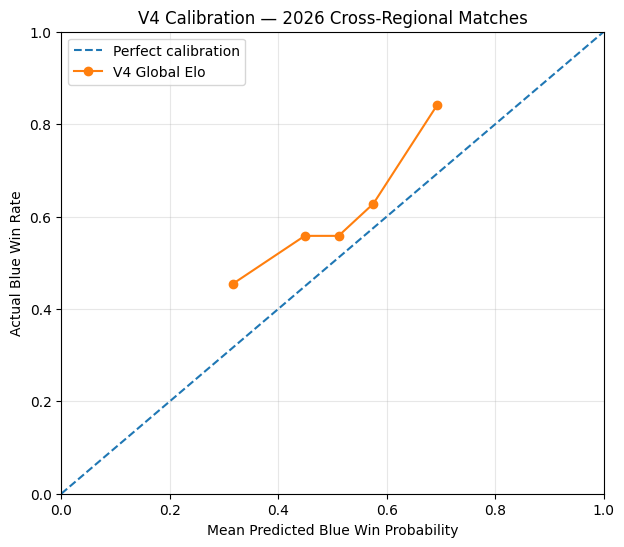

,Mean Predicted Probability,Actual Win Rate
0,31.65%,45.45%
1,44.87%,55.81%
2,51.11%,55.81%
3,57.53%,62.79%
4,69.27%,84.09%


In [23]:

# STEP 23: Calibration analysis for 2026 cross-region matches

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

calibration_df = cross_region_df[
    cross_region_df["year"] == 2026
].copy()

y_true = calibration_df["blue_win"].to_numpy()
y_prob = calibration_df["v4_blue_prob"].to_numpy()

# Divide predictions into 5 approximately equal-sized groups
fraction_positive, mean_predicted = calibration_curve(
    y_true,
    y_prob,
    n_bins=5,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="V4 Global Elo"
)

plt.xlabel("Mean Predicted Blue Win Probability")
plt.ylabel("Actual Blue Win Rate")
plt.title("V4 Calibration — 2026 Cross-Regional Matches")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

calibration_summary = pd.DataFrame({
    "Mean Predicted Probability": mean_predicted,
    "Actual Win Rate": fraction_positive
})

display(
    calibration_summary.style.format({
        "Mean Predicted Probability": "{:.2%}",
        "Actual Win Rate": "{:.2%}"
    })
)


In [24]:

# STEP 24: Check Blue-side bias across years

blue_side_summary = (
    cross_region_df
    .groupby("year")
    .agg(
        Matches=("blue_win", "size"),
        Actual_Blue_Win_Rate=("blue_win", "mean"),
        Mean_Predicted_Blue_Prob=("v4_blue_prob", "mean")
    )
    .reset_index()
)

blue_side_summary["Difference_pp"] = (
    blue_side_summary["Actual_Blue_Win_Rate"]
    - blue_side_summary["Mean_Predicted_Blue_Prob"]
) * 100

display(
    blue_side_summary.style.format({
        "Actual_Blue_Win_Rate": "{:.2%}",
        "Mean_Predicted_Blue_Prob": "{:.2%}",
        "Difference_pp": "{:+.2f}"
    })
)


,year,Matches,Actual_Blue_Win_Rate,Mean_Predicted_Blue_Prob,Difference_pp
0,2024,183,55.19%,50.48%,+4.71
1,2025,196,51.53%,50.11%,+1.42
2,2026,217,60.83%,50.88%,+9.95


In [25]:

# STEP 25: Tune Blue-side bonus using 2024–2025 only

import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, brier_score_loss

train = cross_region_df[
    cross_region_df["year"].isin([2024, 2025])
].copy()

test = cross_region_df[
    cross_region_df["year"] == 2026
].copy()

bonuses = [-40, -20, 0, 20, 40, 60]

results = []

for bonus in bonuses:

    # Elo ratings are already PRE-MATCH values
    elo_diff = (
        train["v4_blue_elo"]
        - train["v4_red_elo"]
    )

    probabilities = 1 / (
        1 + 10 ** (-(elo_diff + bonus) / 400)
    )

    results.append({
        "Blue Bonus": bonus,
        "Train Matches": len(train),
        "Train Log Loss": log_loss(
            train["blue_win"],
            probabilities,
            labels=[0, 1]
        ),
        "Train Brier": brier_score_loss(
            train["blue_win"],
            probabilities
        )
    })

bonus_results = pd.DataFrame(results).sort_values(
    "Train Log Loss"
)

best_bonus = int(bonus_results.iloc[0]["Blue Bonus"])

print("Selected Blue-side bonus:", best_bonus)

display(
    bonus_results.style.format({
        "Train Log Loss": "{:.4f}",
        "Train Brier": "{:.4f}"
    })
)


Selected Blue-side bonus: 20


,Blue Bonus,Train Matches,Train Log Loss,Train Brier
3,20,379,0.6859,0.2461
4,40,379,0.6871,0.2468
2,0,379,0.6878,0.2469
5,60,379,0.6914,0.2488
1,-20,379,0.6928,0.2490
0,-40,379,0.7010,0.2525


In [26]:

# STEP 26: Evaluate Blue-side bonus on 2026 matches

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import numpy as np
import pandas as pd

test = cross_region_df[
    cross_region_df["year"] == 2026
].copy()

y = test["blue_win"].to_numpy()

# Original V4 predictions
original_probs = test["v4_blue_prob"].to_numpy()

# Apply the bonus selected using 2024-2025 data
elo_diff = (
    test["v4_blue_elo"] - test["v4_red_elo"]
).to_numpy()

bonus_probs = 1 / (
    1 + 10 ** (-(elo_diff + best_bonus) / 400)
)

comparison = pd.DataFrame([
    {
        "Model": "V4 Original",
        "Matches": len(test),
        "Accuracy": accuracy_score(y, original_probs >= 0.5),
        "Log Loss": log_loss(y, original_probs, labels=[0, 1]),
        "Brier Score": brier_score_loss(y, original_probs),
        "Mean Predicted Blue Win": original_probs.mean()
    },
    {
        "Model": f"V4 + Blue Bonus ({best_bonus:+d})",
        "Matches": len(test),
        "Accuracy": accuracy_score(y, bonus_probs >= 0.5),
        "Log Loss": log_loss(y, bonus_probs, labels=[0, 1]),
        "Brier Score": brier_score_loss(y, bonus_probs),
        "Mean Predicted Blue Win": bonus_probs.mean()
    }
])

display(
    comparison.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}",
        "Mean Predicted Blue Win": "{:.2%}"
    })
)

print(f"Actual Blue Win Rate: {y.mean():.2%}")


,Model,Matches,Accuracy,Log Loss,Brier Score,Mean Predicted Blue Win
0,V4 Original,217,59.45%,0.6518,0.2304,50.88%
1,V4 + Blue Bonus (+20),217,61.75%,0.6419,0.2258,53.56%


Actual Blue Win Rate: 60.83%


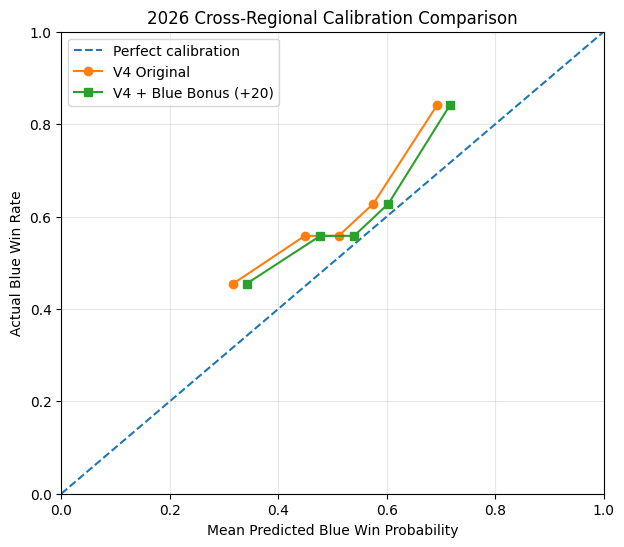

,Original Predicted,Original Actual,Bonus Predicted,Bonus Actual
0,31.65%,45.45%,34.15%,45.45%
1,44.87%,55.81%,47.73%,55.81%
2,51.11%,55.81%,53.98%,55.81%
3,57.53%,62.79%,60.31%,62.79%
4,69.27%,84.09%,71.63%,84.09%


In [27]:

# STEP 27: Compare calibration before and after Blue-side adjustment

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.calibration import calibration_curve

original_actual, original_predicted = calibration_curve(
    y, original_probs, n_bins=5, strategy="quantile"
)

bonus_actual, bonus_predicted = calibration_curve(
    y, bonus_probs, n_bins=5, strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    "--", label="Perfect calibration"
)

plt.plot(
    original_predicted, original_actual,
    marker="o", label="V4 Original"
)

plt.plot(
    bonus_predicted, bonus_actual,
    marker="s", label=f"V4 + Blue Bonus ({best_bonus:+d})"
)

plt.xlabel("Mean Predicted Blue Win Probability")
plt.ylabel("Actual Blue Win Rate")
plt.title("2026 Cross-Regional Calibration Comparison")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

calibration_comparison = pd.DataFrame({
    "Original Predicted": original_predicted,
    "Original Actual": original_actual,
    "Bonus Predicted": bonus_predicted,
    "Bonus Actual": bonus_actual
})

display(
    calibration_comparison.style.format({
        "Original Predicted": "{:.2%}",
        "Original Actual": "{:.2%}",
        "Bonus Predicted": "{:.2%}",
        "Bonus Actual": "{:.2%}"
    })
)


In [28]:

# STEP 28: Inspect international matches with missing region labels

missing_region_matches = v4_international[
    v4_international[
        ["blue_region", "red_region"]
    ].isna().any(axis=1)
].copy()

display(
    missing_region_matches[
        ["date", "year", "league",
         "blue_team", "blue_region",
         "red_team", "red_region",
         "blue_win"]
    ].sort_values("date")
)

print("Missing-region matches:", len(missing_region_matches))


,date,year,league,blue_team,blue_region,red_team,red_region,blue_win
590,2026-07-15 09:51:47,2026,EWC,Sentinels,North America,Team Secret,NaN,1
597,2026-07-15 14:09:45,2026,EWC,Karmine Corp,Europe,Team Secret,NaN,1
599,2026-07-15 15:04:51,2026,EWC,Karmine Corp,Europe,Team Secret,NaN,0
602,2026-07-15 16:10:59,2026,EWC,Team Secret,NaN,Karmine Corp,Europe,0


Missing-region matches: 4


In [29]:

# STEP 29: Inspect Team Secret and Team Secret Whales histories

teams_to_check = ["Team Secret", "Team Secret Whales"]

team_history = pd.concat([
    v4_matches[
        v4_matches["blue_team"].isin(teams_to_check)
    ][["date", "year", "league", "blue_team"]].rename(
        columns={"blue_team": "team"}
    ),
    v4_matches[
        v4_matches["red_team"].isin(teams_to_check)
    ][["date", "year", "league", "red_team"]].rename(
        columns={"red_team": "team"}
    )
], ignore_index=True)

history_summary = (
    team_history.groupby(["team", "year", "league"])
    .agg(
        games=("date", "size"),
        first_match=("date", "min"),
        last_match=("date", "max")
    )
    .reset_index()
    .sort_values(["team", "year", "first_match"])
)

display(history_summary)


,team,year,league,games,first_match,last_match
0,Team Secret,2024,VCS,70,2024-01-20 10:07:51,2024-08-10 14:53:47
1,Team Secret,2026,EWC,4,2026-07-15 09:51:47,2026-07-15 16:10:59
2,Team Secret Whales,2025,LCP,72,2025-01-18 10:26:59,2025-09-21 12:17:52
3,Team Secret Whales,2025,WLDs,6,2025-10-15 05:18:22,2025-10-23 10:01:02
5,Team Secret Whales,2026,LCP,79,2026-01-16 06:23:26,2026-08-30 10:26:53
4,Team Secret Whales,2026,FST,6,2026-03-16 17:26:29,2026-03-18 17:28:38
6,Team Secret Whales,2026,MSI,10,2026-07-03 03:13:25,2026-07-08 04:52:49
7,Team Secret Whales,2026,WLDs,4,2026-10-24 00:11:57,2026-10-26 20:01:50


In [30]:

# STEP 30: Correct the confirmed 2026 EWC team alias

v4_clean_fixed = v4_clean.copy()

ewc_2026_mask = (
    (v4_clean_fixed["league"] == "EWC") &
    (v4_clean_fixed["year"] == 2026)
)

for column in ["blue_team", "red_team"]:
    mask = (
        ewc_2026_mask &
        (v4_clean_fixed[column] == "Team Secret")
    )
    v4_clean_fixed.loc[mask, column] = "Team Secret Whales"

# Verify the change
fixed_ewc = v4_clean_fixed[ewc_2026_mask]

secret_games = fixed_ewc[
    (fixed_ewc["blue_team"] == "Team Secret Whales") |
    (fixed_ewc["red_team"] == "Team Secret Whales")
]

print("Corrected 2026 EWC games:", len(secret_games))

print(
    "Remaining Team Secret entries in 2026 EWC:",
    (
        (fixed_ewc["blue_team"] == "Team Secret") |
        (fixed_ewc["red_team"] == "Team Secret")
    ).sum()
)

display(
    secret_games[
        ["date", "league", "blue_team", "red_team", "blue_win"]
    ]
)


Corrected 2026 EWC games: 4
Remaining Team Secret entries in 2026 EWC: 0


,date,league,blue_team,red_team,blue_win
8768,2026-07-15 09:51:47,EWC,Sentinels,Team Secret Whales,1
8775,2026-07-15 14:09:45,EWC,Karmine Corp,Team Secret Whales,1
8777,2026-07-15 15:04:51,EWC,Karmine Corp,Team Secret Whales,0
8780,2026-07-15 16:10:59,EWC,Team Secret Whales,Karmine Corp,0


In [31]:

# STEP 31: Recalculate V4 Elo after correcting Team Secret alias

import pandas as pd

INITIAL_ELO = 1500
K = 24
ALPHA = 0.75
BLUE_BONUS = 20

ratings_fixed = {}
last_year_fixed = {}
records_fixed = []

for row in v4_clean_fixed.sort_values(
    ["date", "gameid"]
).itertuples(index=False):

    blue_team = row.blue_team
    red_team = row.red_team

    for team in [blue_team, red_team]:
        if team not in ratings_fixed:
            ratings_fixed[team] = INITIAL_ELO
            last_year_fixed[team] = row.year

        elif last_year_fixed[team] != row.year:
            ratings_fixed[team] = (
                INITIAL_ELO
                + ALPHA * (ratings_fixed[team] - INITIAL_ELO)
            )
            last_year_fixed[team] = row.year

    blue_elo = ratings_fixed[blue_team]
    red_elo = ratings_fixed[red_team]

    elo_diff = blue_elo - red_elo

    # Base probability used for rating updates
    base_prob = 1 / (
        1 + 10 ** (-elo_diff / 400)
    )

    # Blue-side adjusted probability for prediction
    adjusted_prob = 1 / (
        1 + 10 ** (-(elo_diff + BLUE_BONUS) / 400)
    )

    records_fixed.append({
        "gameid": row.gameid,
        "v4_blue_elo": blue_elo,
        "v4_red_elo": red_elo,
        "v4_blue_prob": base_prob,
        "v4_adjusted_prob": adjusted_prob
    })

    # Keep original Elo update logic
    ratings_fixed[blue_team] = (
        blue_elo + K * (row.blue_win - base_prob)
    )
    ratings_fixed[red_team] = (
        red_elo + K * (base_prob - row.blue_win)
    )

predictions_fixed = pd.DataFrame(records_fixed)

v4_model_fixed = v4_clean_fixed.merge(
    predictions_fixed,
    on="gameid",
    how="left",
    validate="one_to_one"
)

# Compare old and corrected probabilities
comparison_fixed = v4_model_fixed[
    ["gameid", "v4_blue_prob"]
].merge(
    v4_model_df[["gameid", "v4_blue_prob"]],
    on="gameid",
    suffixes=("_new", "_old"),
    validate="one_to_one"
)

changed = (
    (comparison_fixed["v4_blue_prob_new"]
     - comparison_fixed["v4_blue_prob_old"]).abs()
    > 1e-10
)

print("Total games:", len(v4_model_fixed))
print("Missing predictions:",
      v4_model_fixed["v4_adjusted_prob"].isna().sum())
print("Tracked teams:", len(ratings_fixed))
print("Games with changed base predictions:", changed.sum())

display(
    v4_model_fixed.loc[
        v4_model_fixed["gameid"].isin(
            v4_clean_fixed.loc[
                (v4_clean_fixed["league"] == "EWC") &
                (v4_clean_fixed["year"] == 2026) &
                (
                    (v4_clean_fixed["blue_team"] == "Team Secret Whales") |
                    (v4_clean_fixed["red_team"] == "Team Secret Whales")
                ),
                "gameid"
            ]
        ),
        ["date", "blue_team", "red_team",
         "v4_blue_prob", "v4_adjusted_prob"]
    ]
)


Total games: 9863
Missing predictions: 0
Tracked teams: 186
Games with changed base predictions: 692


,date,blue_team,red_team,v4_blue_prob,v4_adjusted_prob
8768,2026-07-15 09:51:47,Sentinels,Team Secret Whales,0.252735,0.275090
8775,2026-07-15 14:09:45,Karmine Corp,Team Secret Whales,0.456125,0.484799
8777,2026-07-15 15:04:51,Karmine Corp,Team Secret Whales,0.493581,0.522348
8780,2026-07-15 16:10:59,Team Secret Whales,Karmine Corp,0.540426,0.568856


In [32]:

# STEP 32: Re-evaluate corrected V4 on 2026 cross-region games

from sklearn.metrics import accuracy_score, log_loss, brier_score_loss
import pandas as pd

# Attach updated team names and predictions to region labels
updated_international = v4_model_fixed[
    v4_model_fixed["league"].isin(
        ["MSI", "WLDs", "FST", "EWC"]
    )
].copy()

updated_international = updated_international.merge(
    blue_regions,
    on=["year", "blue_team"],
    how="left",
    validate="many_to_one"
).merge(
    red_regions,
    on=["year", "red_team"],
    how="left",
    validate="many_to_one"
)

updated_international["cross_region"] = (
    updated_international["blue_region"].notna()
    & updated_international["red_region"].notna()
    & (
        updated_international["blue_region"]
        != updated_international["red_region"]
    )
)

test_2026 = updated_international[
    (updated_international["year"] == 2026)
    & updated_international["cross_region"]
].copy()

# Match old predictions by game ID for a fair comparison
old_predictions = v4_model_df[
    ["gameid", "v4_blue_prob"]
].rename(columns={
    "v4_blue_prob": "old_prob"
})

test_2026 = test_2026.merge(
    old_predictions,
    on="gameid",
    how="left",
    validate="one_to_one"
)

def evaluate_model(name, probabilities):
    actual = test_2026["blue_win"]
    return {
        "Model": name,
        "Matches": len(actual),
        "Accuracy": accuracy_score(
            actual, probabilities >= 0.5
        ),
        "Log Loss": log_loss(
            actual, probabilities, labels=[0, 1]
        ),
        "Brier Score": brier_score_loss(
            actual, probabilities
        )
    }

final_comparison = pd.DataFrame([
    evaluate_model(
        "Original V4",
        test_2026["old_prob"]
    ),
    evaluate_model(
        "Corrected V4",
        test_2026["v4_blue_prob"]
    ),
    evaluate_model(
        "Corrected V4 +20",
        test_2026["v4_adjusted_prob"]
    )
])

print("2026 cross-region matches:", len(test_2026))
print(
    "2026 missing-region matches:",
    updated_international[
        updated_international["year"] == 2026
    ][["blue_region", "red_region"]]
    .isna().any(axis=1).sum()
)

display(
    final_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}"
    })
)


2026 cross-region matches: 221
2026 missing-region matches: 0


,Model,Matches,Accuracy,Log Loss,Brier Score
0,Original V4,221,59.28%,0.6527,0.2308
1,Corrected V4,221,59.28%,0.6548,0.2318
2,Corrected V4 +20,221,60.63%,0.6450,0.2272


In [33]:

# STEP 33: Export final global Elo ratings for Streamlit

import pandas as pd

latest_affiliations = (
    primary_regions
    .sort_values(["year", "domestic_games"])
    .drop_duplicates("team", keep="last")
    [["team", "primary_league", "region", "year"]]
)

v4_ratings_export = pd.DataFrame({
    "team": list(ratings_fixed.keys()),
    "elo": list(ratings_fixed.values())
})

v4_ratings_export = v4_ratings_export.merge(
    latest_affiliations,
    on="team",
    how="left",
    validate="one_to_one"
)

v4_ratings_export = (
    v4_ratings_export
    .sort_values("elo", ascending=False)
    .reset_index(drop=True)
)

print("Total teams:", len(v4_ratings_export))
print(
    "Teams without region:",
    v4_ratings_export["region"].isna().sum()
)

display(v4_ratings_export.head(15))

v4_ratings_export.to_csv(
    "international_team_ratings.csv",
    index=False
)

print("\nSaved: international_team_ratings.csv")


Total teams: 186
Teams without region: 0


,team,elo,primary_league,region,year
0,Gen.G,1863.591115,LCK,Korea,2026
1,FENNEL,1759.857541,LJL,Asia Pacific,2026
2,Bilibili Gaming,1755.929172,LPL,China,2026
3,REJECT,1755.159431,LJL,Asia Pacific,2025
4,Hanwha Life Esports,1739.970191,LCK,Korea,2026
5,Karmine Corp,1733.043410,LEC,Europe,2026
6,Dplus Kia,1732.569446,LCK,Korea,2026
7,T1,1728.307351,LCK,Korea,2026
8,LYON,1710.448564,LCS,North America,2026
9,Team Liquid,1705.449780,LCS,North America,2026



Saved: international_team_ratings.csv


In [34]:

# STEP 34: Download V4 ratings CSV

from google.colab import files

files.download("international_team_ratings.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>